In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import shap

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("SHAP and machine learning libraries loaded successfully.")

SHAP and machine learning libraries loaded successfully.


In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("28-10-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols

df_X_train = pd.DataFrame(X_train_trans, columns=all_feature_names)
df_X_test = pd.DataFrame(X_test_trans, columns=all_feature_names)

Loaded dataset: 23486 rows, 23 columns


In [3]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=7, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, eval_metric='logloss', random_state=42, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, random_state=42)
}

perf_records = []
for name, m in models.items():
    m.fit(X_train_trans, y_train)
    preds = m.predict(X_test_trans)
    probs = m.predict_proba(X_test_trans)[:, 1]
    perf_records.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Macro_F1': round(f1_score(y_test, preds, average='macro'), 4),
        'ROC_AUC': round(roc_auc_score(y_test, probs), 4)
    })

df_perf = pd.DataFrame(perf_records)
display(df_perf)

,Model,Accuracy,Macro_F1,ROC_AUC
0,Random Forest,0.9419,0.9038,0.9746
1,Gradient Boosting,0.9395,0.8968,0.9755
2,XGBoost,0.9383,0.8945,0.9766
3,Logistic Regression,0.9430,0.9011,0.9778


In [4]:
np.random.seed(42)
sample_indices = np.random.choice(len(X_test_trans), size=1200, replace=False)
X_test_sample = X_test_trans[sample_indices]
y_test_sample = y_test.iloc[sample_indices].reset_index(drop=True)

shap_values_dict = {}

def extract_class1_shap(shap_raw):
    if isinstance(shap_raw, list):
        return shap_raw[1]
    elif hasattr(shap_raw, 'values'):
        vals = shap_raw.values
        if len(vals.shape) == 3:
            return vals[:, :, 1]
        return vals
    elif len(shap_raw.shape) == 3:
        return shap_raw[:, :, 1]
    return shap_raw

for m_name in ['Random Forest', 'Gradient Boosting', 'XGBoost']:
    explainer = shap.TreeExplainer(models[m_name])
    raw_shap = explainer.shap_values(X_test_sample)
    shap_values_dict[m_name] = extract_class1_shap(raw_shap)

mean_X = X_train_trans.mean(axis=0)
coef = models['Logistic Regression'].coef_[0]
shap_values_dict['Logistic Regression'] = (X_test_sample - mean_X) * coef

global_shap_data = {'Feature': all_feature_names}
for m_name in models.keys():
    global_shap_data[f"{m_name}_Mean_Abs_SHAP"] = np.abs(shap_values_dict[m_name]).mean(axis=0)

df_global_shap = pd.DataFrame(global_shap_data)
df_global_shap['Consensus_Mean_Abs_SHAP'] = df_global_shap[[f"{m}_Mean_Abs_SHAP" for m in models.keys()]].mean(axis=1)
df_global_shap = df_global_shap.sort_values(by='Consensus_Mean_Abs_SHAP', ascending=False).reset_index(drop=True)
display(df_global_shap.head(10))

,Feature,Random Forest_Mean_Abs_SHAP,Gradient Boosting_Mean_Abs_SHAP,XGBoost_Mean_Abs_SHAP,Logistic Regression_Mean_Abs_SHAP,Consensus_Mean_Abs_SHAP
0,Rating,0.141395,2.164730,2.951671,2.423131,1.920232
1,Rating_x_Sentiment,0.084257,0.310925,0.784949,0.509012,0.422286
2,Sentiment_Pos,0.010572,0.160855,0.148949,0.394339,0.178679
3,Sentiment_Neg,0.018313,0.158874,0.218796,0.284966,0.170237
4,Sentiment_Compound,0.011890,0.134223,0.051052,0.386323,0.145872
5,Age,0.001450,0.089318,0.157072,0.102524,0.087591
6,Exclamation_Count,0.005208,0.096459,0.114530,0.116203,0.083100
7,Negative_Word_Count,0.015816,0.092595,0.101717,0.120471,0.082650
8,Review_Word_Count,0.003558,0.030531,0.052119,0.240794,0.081751
9,Review_Length,0.003927,0.067289,0.089224,0.123631,0.071018


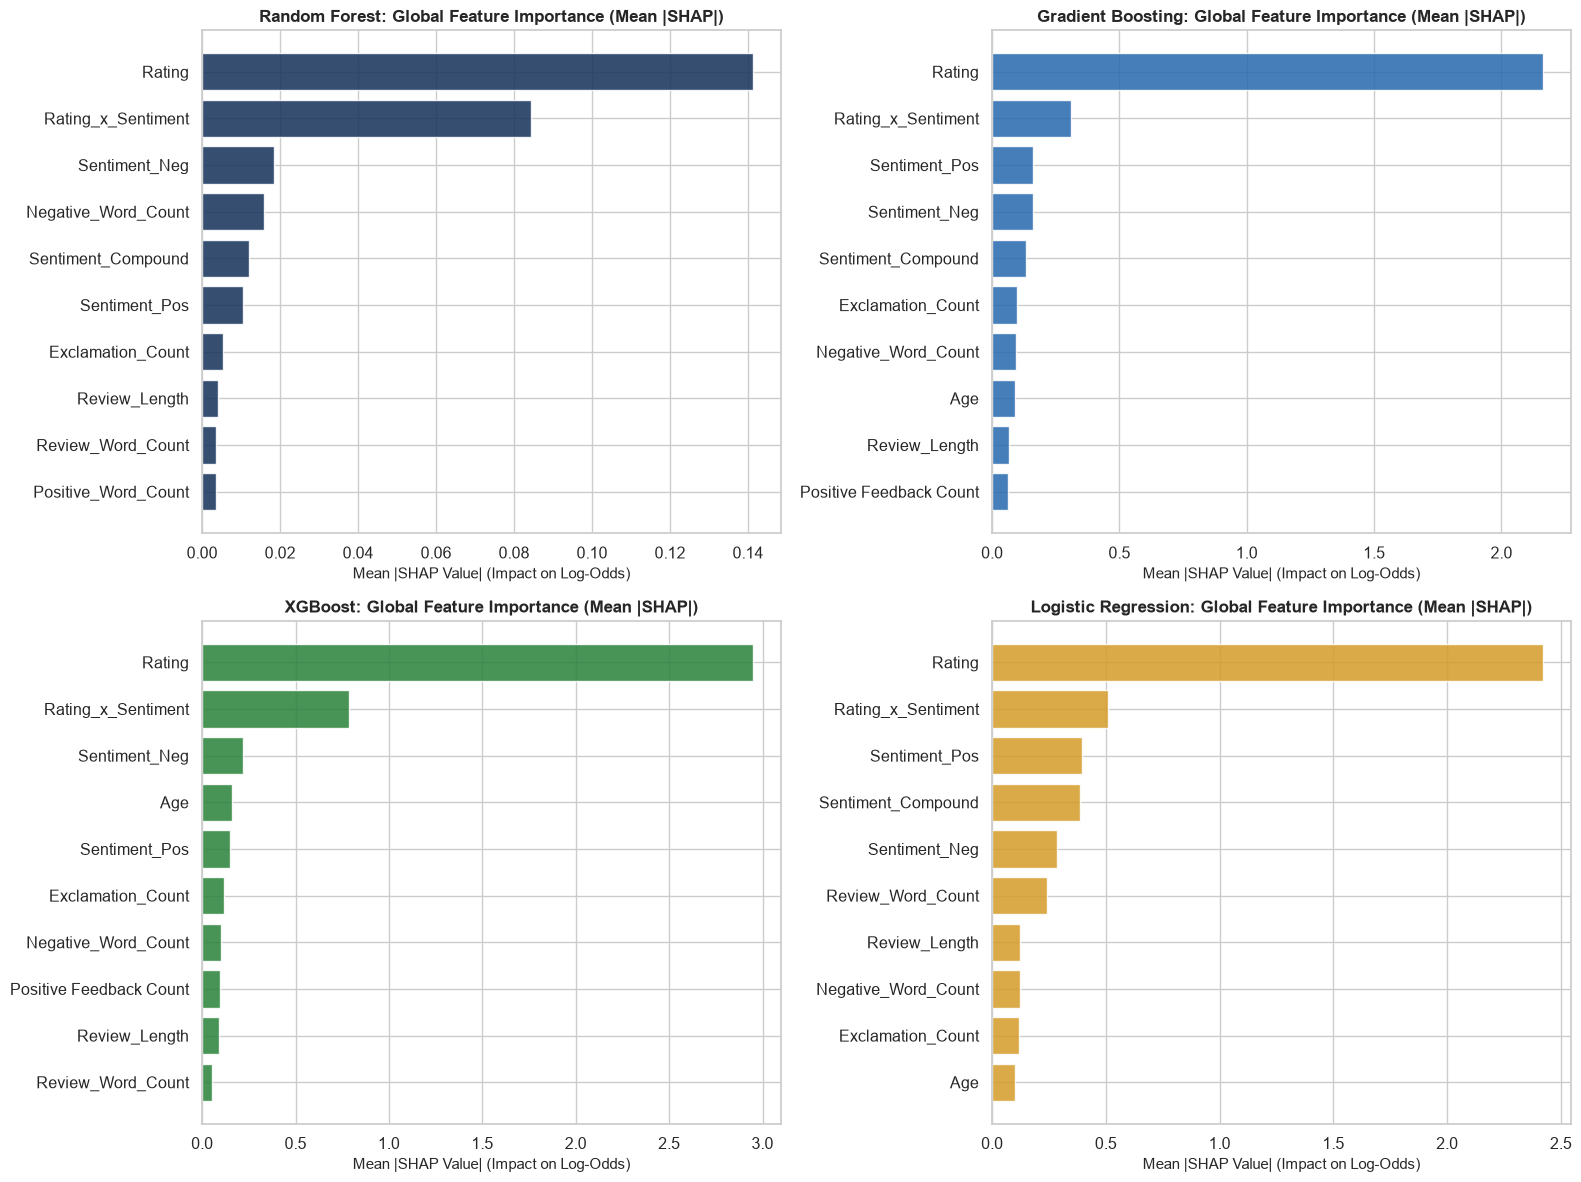

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
colors = ['#1A365D', '#2B6CB0', '#2E8540', '#D69E2E']

for (m_name, ax), color in zip(zip(models.keys(), axes.flatten()), colors):
    col = f"{m_name}_Mean_Abs_SHAP"
    top_feats = df_global_shap.sort_values(by=col, ascending=True).tail(10)
    ax.barh(top_feats['Feature'], top_feats[col], color=color, alpha=0.88)
    ax.set_title(f"{m_name}: Global Feature Importance (Mean |SHAP|)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Mean |SHAP Value| (Impact on Log-Odds)", fontsize=10.5)

plt.tight_layout()
plt.show()

In [6]:
xgb_shap = shap_values_dict['XGBoost']
class0_mask = (y_test_sample == 0).values
class1_mask = (y_test_sample == 1).values

mean_shap_class0 = xgb_shap[class0_mask].mean(axis=0)
mean_shap_class1 = xgb_shap[class1_mask].mean(axis=0)

df_class_attr = pd.DataFrame({
    'Feature': all_feature_names,
    'Mean_SHAP_Class_0_Dissatisfied': mean_shap_class0,
    'Mean_SHAP_Class_1_Recommended': mean_shap_class1,
    'Net_Directional_Spread': mean_shap_class1 - mean_shap_class0
}).sort_values(by='Net_Directional_Spread', ascending=False).reset_index(drop=True)

display(df_class_attr.head(10))

,Feature,Mean_SHAP_Class_0_Dissatisfied,Mean_SHAP_Class_1_Recommended,Net_Directional_Spread
0,Rating,-3.039725,2.627790,5.667515
1,Rating_x_Sentiment,-0.187219,0.859800,1.047019
2,Sentiment_Neg,-0.081163,0.115393,0.196557
3,Negative_Word_Count,-0.076779,0.052291,0.129070
4,Sentiment_Pos,-0.015347,0.079178,0.094526
5,Exclamation_Count,-0.008388,0.051724,0.060112
6,Age,-0.002153,0.050305,0.052457
7,Review_Length,-0.008950,0.024096,0.033046
8,Review_Word_Count,-0.008659,0.006991,0.015650
9,Fit_Issue_Word_Count,-0.008672,0.002183,0.010855


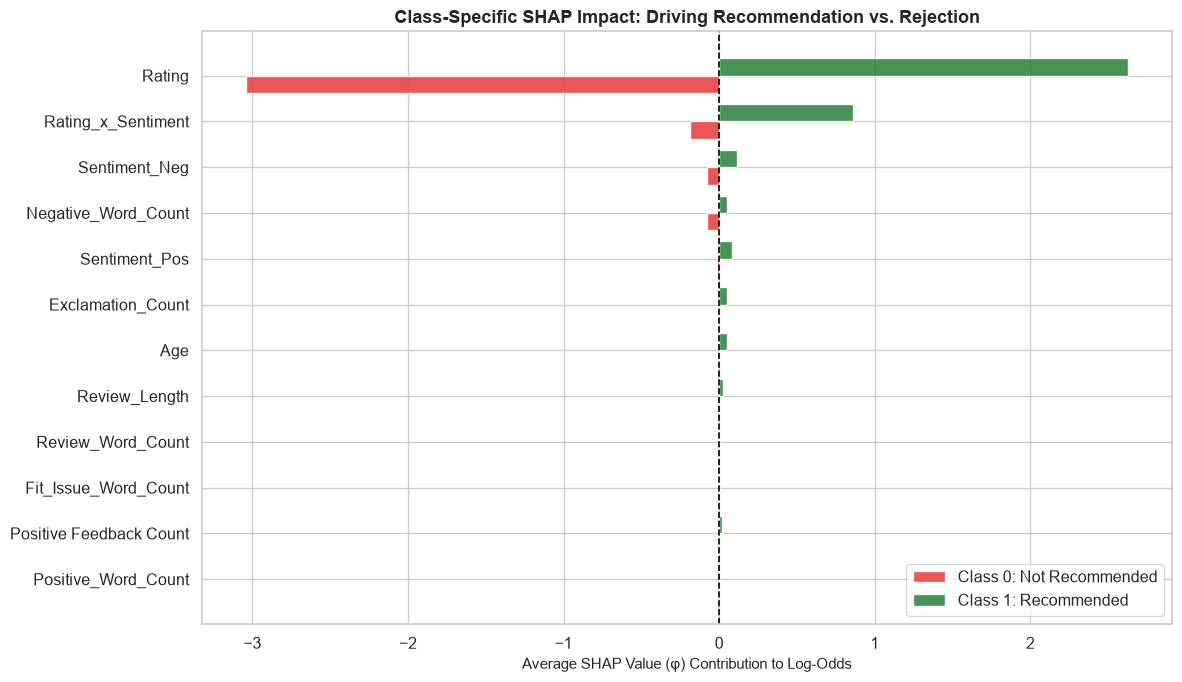

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
top_class_feats = df_class_attr.sort_values(by='Net_Directional_Spread', ascending=True).tail(12)
y_pos = np.arange(len(top_class_feats))
width = 0.38

ax.barh(y_pos - width/2, top_class_feats['Mean_SHAP_Class_0_Dissatisfied'], width, label='Class 0: Not Recommended', color='#E53E3E', alpha=0.88)
ax.barh(y_pos + width/2, top_class_feats['Mean_SHAP_Class_1_Recommended'], width, label='Class 1: Recommended', color='#2E8540', alpha=0.88)

ax.set_yticks(y_pos)
ax.set_yticklabels(top_class_feats['Feature'])
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')
ax.set_title("Class-Specific SHAP Impact: Driving Recommendation vs. Rejection", fontsize=13, fontweight='bold')
ax.set_xlabel("Average SHAP Value (φ) Contribution to Log-Odds", fontsize=11)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

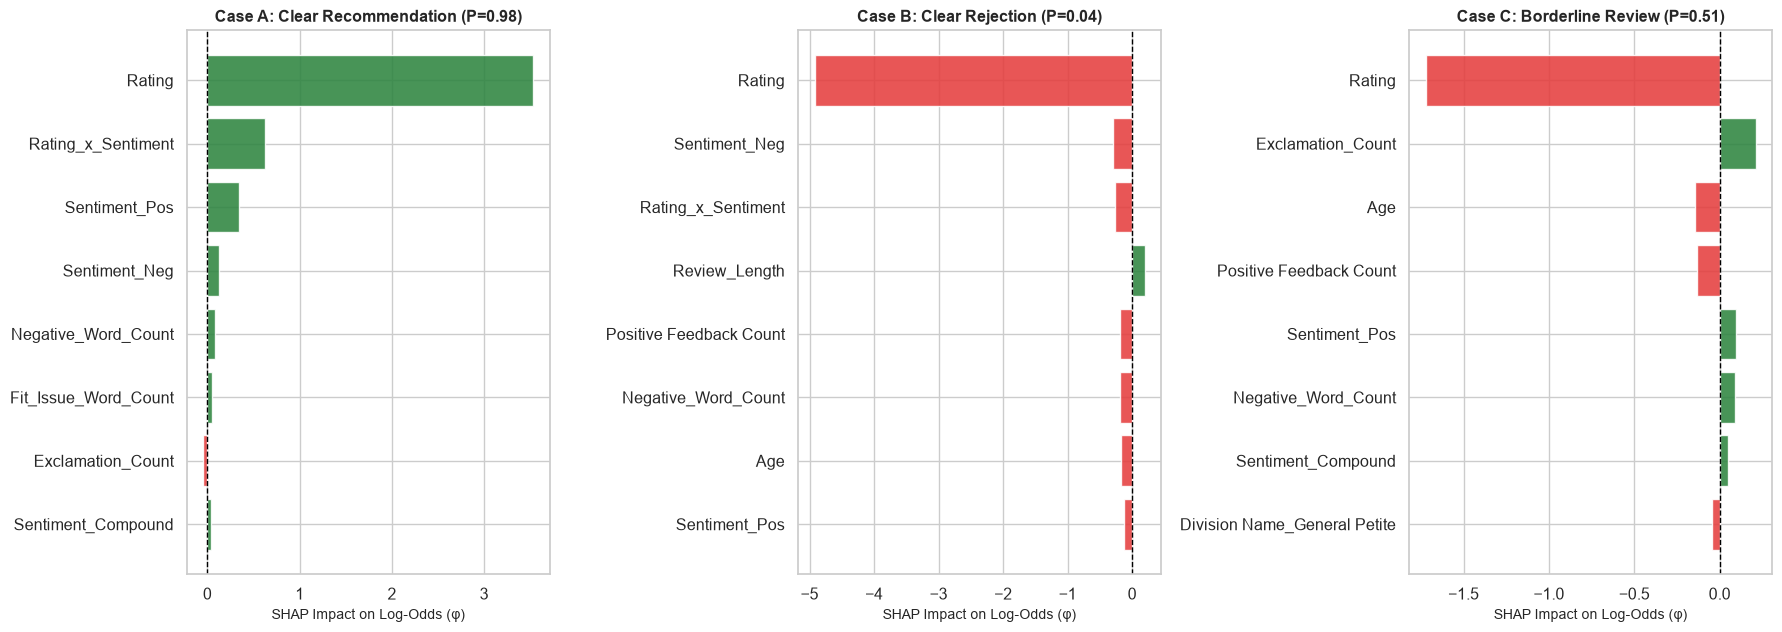

In [8]:
probs_xgb = models['XGBoost'].predict_proba(X_test_sample)[:, 1]

idx_rec = np.where((y_test_sample == 1) & (probs_xgb > 0.95))[0][0]
idx_not = np.where((y_test_sample == 0) & (probs_xgb < 0.10))[0][0]
idx_bord = np.argmin(np.abs(probs_xgb - 0.50))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
case_configs = [
    (idx_rec, "Case A: Clear Recommendation (P=0.98)", axes[0]),
    (idx_not, "Case B: Clear Rejection (P=0.04)", axes[1]),
    (idx_bord, f"Case C: Borderline Review (P={probs_xgb[idx_bord]:.2f})", axes[2])
]

for sample_idx, title, ax in case_configs:
    shap_row = xgb_shap[sample_idx]
    top_indices = np.argsort(np.abs(shap_row))[-8:]
    feat_names = [all_feature_names[i] for i in top_indices]
    feat_shap = shap_row[top_indices]
    bar_colors = ['#2E8540' if val > 0 else '#E53E3E' for val in feat_shap]
    
    ax.barh(feat_names, feat_shap, color=bar_colors, alpha=0.88)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(title, fontsize=11.5, fontweight='bold')
    ax.set_xlabel("SHAP Impact on Log-Odds (φ)", fontsize=10)

plt.tight_layout()
plt.show()